In [21]:
import sqlite3
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


dataset_path = "/Users/sophie/.cache/kagglehub/datasets/nikdavis/steam-store-games/versions/3"

df = pd.read_csv(os.path.join(dataset_path, "steam.csv"))

In [22]:
conn = sqlite3.connect('steam_market.db')

# Сегментация игр по цене и оценка их популярности
query = """
WITH PriceSegmentedGames AS (
    SELECT 
        name,
        price,
        positive_ratings,
        negative_ratings,
        CASE 
            WHEN price = 0 THEN '1. Free (Бесплатные)'
            WHEN price > 0 AND price <= 5 THEN '2. Budget (До $5)'
            WHEN price > 5 AND price <= 15 THEN '3. Mid-core ($5-$15)'
            ELSE '4. Premium (Более $15)'
        END AS price_segment
    FROM games
),
SegmentAggregates AS (
    SELECT 
        price_segment,
        COUNT(name) as total_games,
        ROUND(AVG(price), 2) as avg_price,
        ROUND(AVG(positive_ratings), 0) as avg_positive_ratings,
        ROUND(AVG(negative_ratings), 0) as avg_negative_ratings
    FROM PriceSegmentedGames
    GROUP BY price_segment
)
SELECT 
    price_segment,
    total_games,
    ROUND(CAST(total_games AS REAL) / SUM(total_games) OVER() * 100, 2) as market_share_percent,
    avg_price,
    avg_positive_ratings,
    avg_negative_ratings
FROM SegmentAggregates
ORDER BY price_segment;
"""

pricing_mart = pd.read_sql_query(query, conn)
display(pricing_mart)

conn.close()

,price_segment,total_games,market_share_percent,avg_price,avg_positive_ratings,avg_negative_ratings
0,1. Free (Бесплатные),2560,9.46,0.00,3065.0,630.0
1,2. Budget (До $5),13293,49.10,2.63,144.0,35.0
2,3. Mid-core ($5-$15),9246,34.15,8.78,1042.0,144.0
3,4. Premium (Более $15),1976,7.30,24.49,3898.0,1167.0


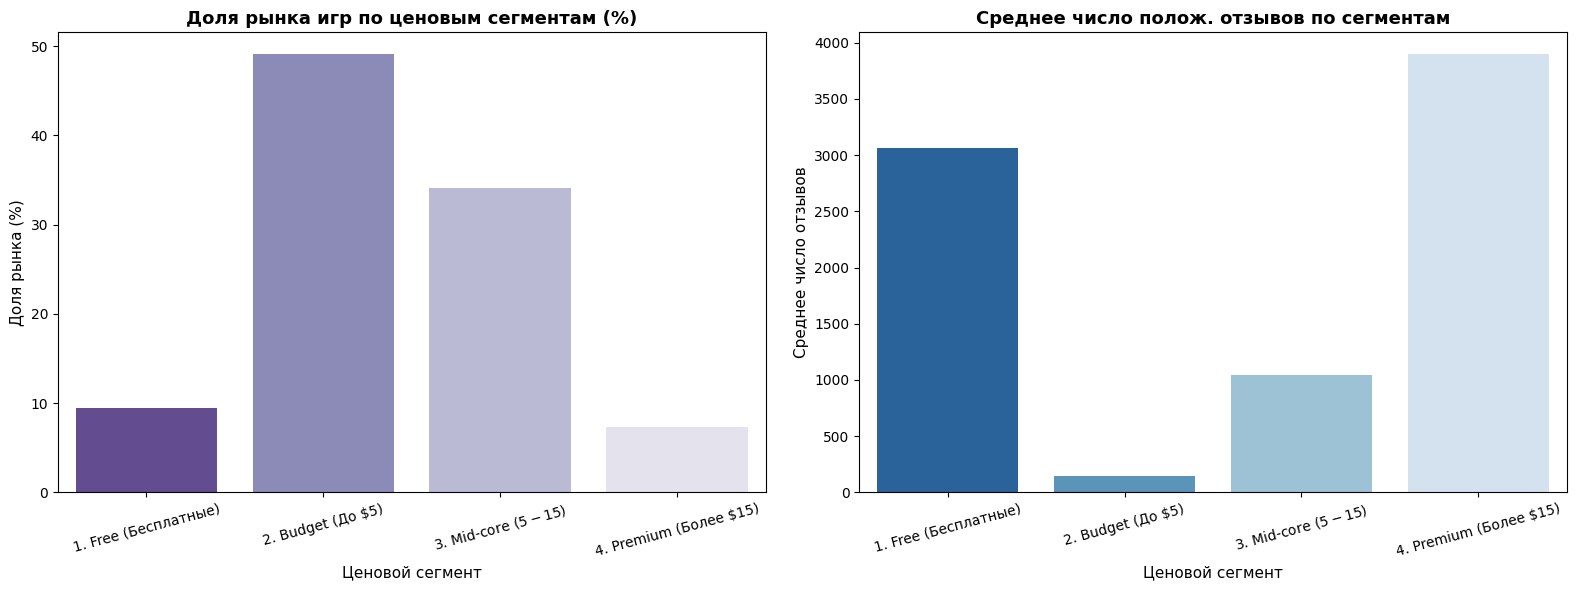

In [23]:
# --- СТРОИМ ВИЗУАЛИЗАЦИЮ НА ОСНОВЕ SQL-ВИТРИНЫ ---

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Доля рынка (количество игр) по ценовым сегментам
sns.barplot(
    data=pricing_mart, 
    x='price_segment', 
    y='market_share_percent', 
    palette='Purples_r', 
    hue='price_segment', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Доля рынка игр по ценовым сегментам (%)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Ценовой сегмент', fontsize=11)
axes[0].set_ylabel('Доля рынка (%)', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)

# График 2: Среднее количество положительных отзывов в сегментах
sns.barplot(
    data=pricing_mart, 
    x='price_segment', 
    y='avg_positive_ratings', 
    palette='Blues_r', 
    hue='price_segment', 
    legend=False, 
    ax=axes[1]
)
axes[1].set_title('Среднее число полож. отзывов по сегментам', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Ценовой сегмент', fontsize=11)
axes[1].set_ylabel('Среднее число отзывов', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Огромная доля рынка - это бюджетные игры (до $5), но самая активная аудитория играет в бесплатные игры или игры premium (более $15)

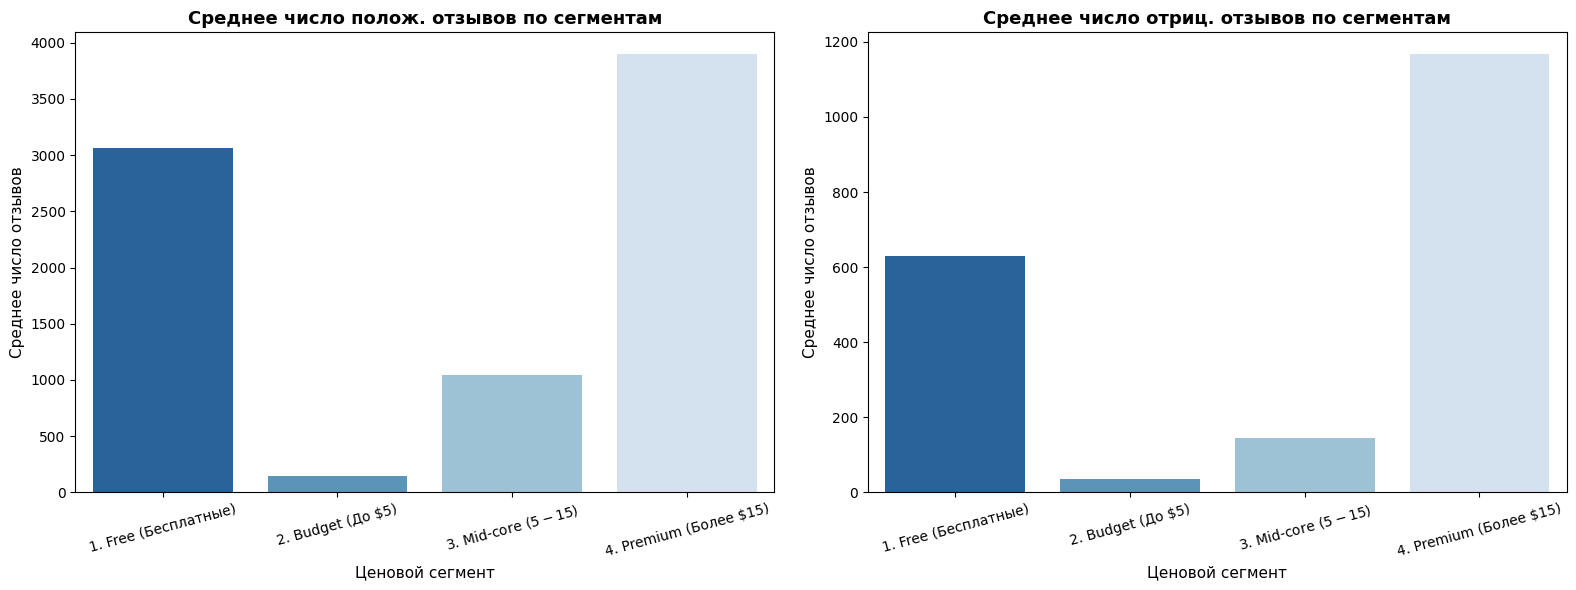

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=pricing_mart, 
    x='price_segment', 
    y='avg_positive_ratings', 
    palette='Blues_r', 
    hue='price_segment', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Среднее число полож. отзывов по сегментам', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Ценовой сегмент', fontsize=11)
axes[0].set_ylabel('Среднее число отзывов', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(
    data=pricing_mart, 
    x='price_segment', 
    y='avg_negative_ratings', 
    palette='Blues_r', 
    hue='price_segment', 
    legend=False, 
    ax=axes[1]
)
axes[1].set_title('Среднее число отриц. отзывов по сегментам', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Ценовой сегмент', fontsize=11)
axes[1].set_ylabel('Среднее число отзывов', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Мы видим, что пропорция сохраняется (у премиум-сегмента и бесплатных игр больше и позитива, и негатива просто в силу огромной аудитории и вовлеченности, а не из-за тотального брака)